## in the name of allah we begin new adventure in AI

In [ ]:
%%capture
!pip install rdkit-pypi
!pip install torch-geometric

In [ ]:
import torch
import rdkit
from rdkit import Chem
from torch_geometric.loader import DataLoader
from IPython import display
from rdkit.Chem.Draw import IPythonConsole
import pandas
import rdkit.Chem.Lipinski as Lipinsky
from rdkit.Chem.Draw import SimilarityMaps
from rdkit import DataStructs
from rdkit.Chem import AllChem
from rdkit.Chem import Draw
from torch_geometric.datasets import MoleculeNet
from torch.nn import Linear
import torch.nn.functional as F
from torch_geometric.nn import GCNConv, TopKPooling, global_mean_pool
from torch_geometric.nn import global_mean_pool, global_max_pool
from torch_geometric.typing import torch_scatter
import matplotlib.pyplot as plt
from IPython.display import clear_output

## load graph data

In [ ]:
data = MoleculeNet(root=".", name="ESOL")
data

ESOL(1128)

## data infos

In [ ]:
# Investigating the dataset
print("\n================================================================")
print("Dataset type: ", type(data))
print("Number of graphs in the dataset: ", len(data))
print("Dataset features (num_features): ", data.num_features)
print("Dataset target classes (num_classes): ", data.num_classes)

# Displaying a sample graph
print("\n================================================================")
sample = data[0]
print("Sample graph:")
print("Number of nodes (atoms): ", sample.num_nodes)
print("Number of edges (bonds): ", sample.num_edges)
print("Node features shape: ", sample.x.shape)
print("Edge index shape (graph connections): ", sample.edge_index.shape)
print("Graph label: ", sample.y, type(sample.y))

# Displaying detailed node and edge information for the sample
print("\n================================================================")
print("Sample node features (first 5 nodes):\n", sample.x[:5])
print("Sample edge index (first 5 edges):\n", sample.edge_index[:, :5])

# Optionally, display SMILES if it's part of the dataset
print("\n================================================================")
if hasattr(sample, 'smiles'):
    print("SMILES representation of the molecule: ", sample.smiles)


Dataset type:  <class 'torch_geometric.datasets.molecule_net.MoleculeNet'>
Number of graphs in the dataset:  1128
Dataset features (num_features):  9
Dataset target classes (num_classes):  734

Sample graph:
Number of nodes (atoms):  32
Number of edges (bonds):  68
Node features shape:  torch.Size([32, 9])
Edge index shape (graph connections):  torch.Size([2, 68])
Graph label:  tensor([[-0.7700]]) <class 'torch.Tensor'>

Sample node features (first 5 nodes):
 tensor([[8, 0, 2, 5, 1, 0, 4, 0, 0],
        [6, 0, 4, 5, 2, 0, 4, 0, 0],
        [6, 0, 4, 5, 1, 0, 4, 0, 1],
        [8, 0, 2, 5, 0, 0, 4, 0, 1],
        [6, 0, 4, 5, 1, 0, 4, 0, 1]])
Sample edge index (first 5 edges):
 tensor([[0, 1, 1, 2, 2],
        [1, 0, 2, 1, 3]])

SMILES representation of the molecule:  OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)C(O)C3O 


/usr/local/lib/python3.10/dist-packages/torch_geometric/data/dataset.py:169: UserWarning: Found floating-point labels while calling `dataset.num_classes`. Returning the number of unique elements. Please make sure that this is expected before proceeding.
  warnings.warn("Found floating-point labels while calling "


In [ ]:
sample.x, sample.y

(tensor([[8, 0, 2, 5, 1, 0, 4, 0, 0],
         [6, 0, 4, 5, 2, 0, 4, 0, 0],
         [6, 0, 4, 5, 1, 0, 4, 0, 1],
         [8, 0, 2, 5, 0, 0, 4, 0, 1],
         [6, 0, 4, 5, 1, 0, 4, 0, 1],
         [8, 0, 2, 5, 0, 0, 4, 0, 0],
         [6, 0, 4, 5, 2, 0, 4, 0, 0],
         [6, 0, 4, 5, 1, 0, 4, 0, 1],
         [8, 0, 2, 5, 0, 0, 4, 0, 1],
         [6, 0, 4, 5, 1, 0, 4, 0, 1],
         [8, 0, 2, 5, 0, 0, 4, 0, 0],
         [6, 0, 4, 5, 1, 0, 4, 0, 0],
         [6, 0, 2, 5, 0, 0, 2, 0, 0],
         [7, 0, 1, 5, 0, 0, 2, 0, 0],
         [6, 0, 3, 5, 0, 0, 3, 1, 1],
         [6, 0, 3, 5, 1, 0, 3, 1, 1],
         [6, 0, 3, 5, 1, 0, 3, 1, 1],
         [6, 0, 3, 5, 1, 0, 3, 1, 1],
         [6, 0, 3, 5, 1, 0, 3, 1, 1],
         [6, 0, 3, 5, 1, 0, 3, 1, 1],
         [6, 0, 4, 5, 1, 0, 4, 0, 1],
         [8, 0, 2, 5, 1, 0, 4, 0, 0],
         [6, 0, 4, 5, 1, 0, 4, 0, 1],
         [8, 0, 2, 5, 1, 0, 4, 0, 0],
         [6, 0, 4, 5, 1, 0, 4, 0, 1],
         [8, 0, 2, 5, 1, 0, 4, 0, 0],
         [6,

In [ ]:
print("Edges in COO format (source node -> target node):")
print(sample.edge_index.t().shape)
print(sample.num_edges)

Edges in COO format (source node -> target node):
torch.Size([68, 2])
68


## displaying SMILES and geomterical representation

In [ ]:
print(sample["smiles"])

OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)C(O)C3O 


In [ ]:
molecule = Chem.MolFromSmiles(sample["smiles"])
type(molecule)

rdkit.Chem.rdchem.Mol

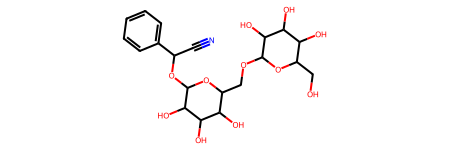

In [ ]:
molecule

## Hyperparameters

In [ ]:
data_size = len(data)
train_size = int(data_size * 0.8)
test_size = int(data_size * 0.1)
val_size = data_size - train_size - test_size  # Remainder for validation

b_size = 64
epochs = 10000
lr = 0.0005
drop_rate = 0.0
in_feature = 9
out_feature = 16

In [ ]:
print(f"testing data size: {test_size}")
print(f"validation data size: {val_size}")
print(f"training data size: {train_size}")

testing data size: 112
validation data size: 114
training data size: 902


## Data Loaders

In [ ]:
train_loader = DataLoader(data[:train_size],
                          batch_size=b_size, shuffle=True)
val_loader = DataLoader(data[train_size: train_size+val_size],
                        batch_size=b_size, shuffle=True)
test_loader = DataLoader(data[train_size+val_size:],
                         batch_size=b_size, shuffle=True)

In [ ]:
for mol in train_loader:
    x, y = mol.x, mol.y
    print(x.shape, y.shape)
    break

torch.Size([813, 9]) torch.Size([64, 1])


## Helpers

In [ ]:
def live_plot(train_losses, val_losses, train_maes, val_maes, train_mses, val_mses, train_rmses, val_rmses, train_r2s, val_r2s):
    clear_output(wait=True)

    plt.figure(figsize=(12, 6))

    # Plot training metrics
    plt.subplot(1, 2, 1)
    plt.plot(train_losses, label='Train Loss', color='blue')
    plt.plot(train_maes, label='Train MAE', color='green')
    plt.plot(train_mses, label='Train MSE', color='red')
    plt.plot(train_rmses, label='Train RMSE', color='purple')
    plt.plot(train_r2s, label='Train R²', color='brown')
    plt.xlabel('Epoch')
    plt.ylabel('Value')
    plt.title('Training Metrics')
    plt.legend()
    plt.grid(True)

    # Plot validation metrics
    plt.subplot(1, 2, 2)
    plt.plot(val_losses, label='Validation Loss', color='blue')
    plt.plot(val_maes, label='Validation MAE', color='green')
    plt.plot(val_mses, label='Validation MSE', color='red')
    plt.plot(val_rmses, label='Validation RMSE', color='purple')
    plt.plot(val_r2s, label='Validation R²', color='brown')
    plt.xlabel('Epoch')
    plt.ylabel('Value')
    plt.title('Validation Metrics')
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()


def compute_metrics(x, y):
    # Convert x and y to tensors if they aren't already
    x = torch.tensor(x) if not isinstance(x, torch.Tensor) else x
    y = torch.tensor(y) if not isinstance(y, torch.Tensor) else y

    # Mean Absolute Error
    mae = torch.mean(torch.abs(x - y)).item()

    # Mean Squared Error
    mse = torch.mean((x - y) ** 2)

    # Root Mean Squared Error
    rmse = torch.sqrt(mse).item()

    # R-squared
    mean_y = torch.mean(y)
    ss_total = torch.sum((y - mean_y) ** 2)
    ss_residual = torch.sum((y - x) ** 2)
    r2 = 1 - (ss_residual / ss_total).item()

    return mae, mse.item(), rmse, r2

def trainer(loader):
    model.train()
    total_loss = 0
    all_preds = []
    all_targets = []

    for batch in loader:
        x, y, e_idx, b_idx = batch.x.float().to(device), batch.y.float().to(device), batch.edge_index.to(device), batch.batch.to(device)

        # Extremely Important
        optimizer.zero_grad()

        # Forward pass
        pred = model(x=x, e_idx=e_idx, b_idx=b_idx)

        # loss
        loss = loss_fn(pred.squeeze(), y.squeeze())
        total_loss += loss.item()

        # Backward pass
        loss.backward()
        optimizer.step()

        # Collect predictions and targets for metrics calculation
        all_preds.append(pred.cpu().detach())
        all_targets.append(y.cpu().detach())

    avg_loss = total_loss / len(loader)

    # Concatenate all predictions and targets
    all_preds = torch.cat(all_preds)
    all_targets = torch.cat(all_targets)

    # Compute metrics
    mae, mse, rmse, r2 = compute_metrics(all_preds, all_targets)

    return avg_loss, mae, mse, rmse, r2

def validator(loader):
    model.eval()
    total_loss = 0
    all_preds = []
    all_targets = []

    with torch.no_grad():
        for batch in loader:
            x, y, e_idx, b_idx = batch.x.float().to(device), batch.y.float().to(device), batch.edge_index.to(device), batch.batch.to(device)

            # Forward pass
            pred = model(x=x, e_idx=e_idx, b_idx=b_idx)

            # Calculate loss
            loss = loss_fn(pred.squeeze(), y.squeeze())
            total_loss += loss.item()

            # Collect predictions and targets for metrics calculation
            all_preds.append(pred.cpu().detach())
            all_targets.append(y.cpu().detach())

    avg_loss = total_loss / len(loader)

    # Concatenate all predictions and targets
    all_preds = torch.cat(all_preds)
    all_targets = torch.cat(all_targets)

    # Compute metrics
    mae, mse, rmse, r2 = compute_metrics(all_preds, all_targets)

    return avg_loss, mae, mse, rmse, r2

## building model

In [ ]:
class GCNModel(torch.nn.Module):
    def __init__(self, in_feature, out_feature, drop_rate=0.0):
        super(GCNModel, self).__init__()
        torch.manual_seed(42)

        # first GCN layer
        self.gcn0 = GCNConv(in_feature, out_feature)

        # GCN layers
        self.gcn1 = GCNConv(out_feature, out_feature)
        self.gcn2 = GCNConv(out_feature, out_feature)
        self.gcn3 = GCNConv(out_feature, out_feature)

        # Dropout layers
        self.dropout = torch.nn.Dropout(p=drop_rate)

        # classifier layer: [gmp_size + gap_size]
        self.ln = Linear(out_feature * 2, 1)

    def get_num_parameters(self):
        return sum(p.numel() for p in self.parameters())

    def forward(self, x, e_idx, b_idx):
        x = self.gcn0(x, e_idx)
        x = F.tanh(x)
        x = self.dropout(x)

        # GCN
        x = self.gcn1(x, e_idx)
        x = F.tanh(x)
        x = self.dropout(x)

        x = self.gcn2(x, e_idx)
        x = F.tanh(x)
        x = self.dropout(x)

        x = self.gcn3(x, e_idx)
        x = F.tanh(x)
        x = self.dropout(x)

        # Global Pooling: [ global max pooling + global average pooling]
        gmp = global_max_pool(x, b_idx)
        gap = global_mean_pool(x, b_idx)
        x = torch.cat([gmp, gap], dim=1)

        # linear classifier
        logits = self.ln(x)

        return logits



model = GCNModel(in_feature=in_feature, out_feature=out_feature, drop_rate=0.2)
# print(model.get_num_parameters())
print(model)

for mol in train_loader:
    x, y, e_idx = mol.x.float(), mol.y.float(), mol.edge_index
    print(f"x.shape: {x.shape}")
    print(f"y.shape: {y.shape}")
    print(f"e_idx.shape: {e_idx.shape}")
    logits = model(x = x, e_idx=e_idx, b_idx=mol.batch)
    print(logits.shape)

    break

GCNModel(
  (gcn0): GCNConv(9, 16)
  (gcn1): GCNConv(16, 16)
  (gcn2): GCNConv(16, 16)
  (gcn3): GCNConv(16, 16)
  (dropout): Dropout(p=0.2, inplace=False)
  (ln): Linear(in_features=32, out_features=1, bias=True)
)
x.shape: torch.Size([710, 9])
y.shape: torch.Size([64, 1])
e_idx.shape: torch.Size([2, 1432])
torch.Size([64, 1])


In [ ]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model = GCNModel(in_feature=in_feature, out_feature=out_feature, drop_rate=drop_rate).to(device)
loss_fn = torch.nn.MSELoss(reduction='mean')
optimizer = torch.optim.Adam(model.parameters(), lr=lr)

## Train the Model

KeyboardInterrupt: 

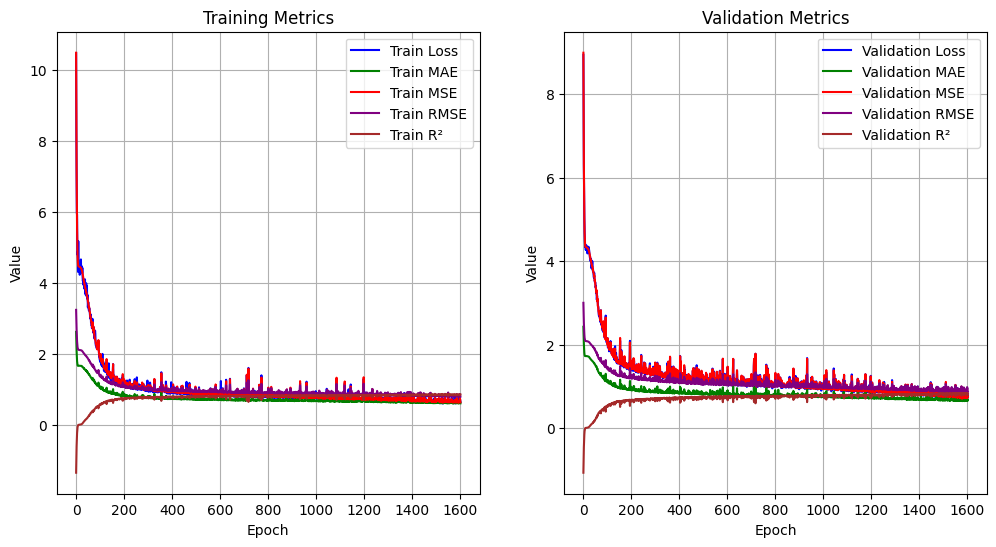

In [ ]:
# Initialize lists to store metrics
train_losses = []
val_losses = []
train_maes = []
val_maes = []
train_mses = []
val_mses = []
train_rmses = []
val_rmses = []
train_r2s = []
val_r2s = []

print("Starting training...")

# Run training for a specified number of epochs
for epoch in range(epochs):
    # Training phase
    tr_loss, tr_mae, tr_mse, tr_rmse, tr_r2 = trainer(train_loader)
    train_losses.append(tr_loss)
    train_maes.append(tr_mae)
    train_mses.append(tr_mse)
    train_rmses.append(tr_rmse)
    train_r2s.append(tr_r2)

    # Validation phase
    val_loss, val_mae, val_mse, val_rmse, val_r2 = validator(val_loader)
    val_losses.append(val_loss)
    val_maes.append(val_mae)
    val_mses.append(val_mse)
    val_rmses.append(val_rmse)
    val_r2s.append(val_r2)

    # Plot live metrics
    live_plot(train_losses, val_losses, train_maes, val_maes, train_mses, val_mses, train_rmses, val_rmses, train_r2s, val_r2s)